<a href="https://colab.research.google.com/github/tharold4096/Tobias_INFO4670_Fall2026/blob/main/Logistic_Regression_Car_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 11: Assignment 4 - Logistic Regression Assignment (Age & Salary → Purchased)
**Coures:** INFO 4670 Fengjiao Tu  
**Goal:** Train and evaluate a Logistic Regression model to predict whether a customer purchases a car using `Age` and `Salary`.

---

## I. Assignment Objective
By completing this assignment, you will:
- Understand the concept and intuition of logistic regression.
- Load and preprocess data using `pandas`.
- Train and evaluate a logistic regression model with `scikit-learn`.
- Visualize classification results.
- Analyze model performance and reflect on possible improvements.


## II. Dataset Description
Expected CSV file name: **`car_purchase_data.csv`**

| Column | Description | Example |
|--------|-------------|---------|
| `Age` | Age of the customer | 35 |
| `Salary` | Annual or monthly income | 60000 |
| `Purchased` | Whether the customer purchased a car (1 = Yes, 0 = No) | 1 |


---
# Grading Rubric (Total = 100 points)

| Section | Description | Points | Details |
|--------|-------------|--------|---------|
| **Objective Understanding** | Explain purpose and logic of logistic regression | 10 | Goal & rationale (5); why LR for this task (5) |
| **Data Preparation** | Data loading, splitting, scaling | 20 | Import & preview (5); X/y split (5); train/test (5); scaling (5) |
| ** Model Training & Evaluation** | Fit, predict, metrics, visualization | 40 | Trained correctly (10); metrics shown (10); **accuracy ≥ 87.5% (10)**; visualization (10) |
| ** Analysis & Reflection** | Interpretation and critical thinking | 30 | Probability→class explanation (10); result discussion (10); improvements (10) |


**Accuracy Requirement:**
- Full credit (10 pts) if **accuracy ≥ 87.5%**
- Partial (7–9 pts) if **80% ≤ accuracy < 87.5%**
- Minimal (≤5 pts) if **accuracy < 80%**
- 0 pts if the model fails to run


## III. Steps to Complete
Follow the cells below in order. According to the hands-on task, please complete the code.

### Step 1: Import libraries and load data

In [1]:
#Please write the code here
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

data = pd.read_csv('car_purchase_data.csv')
display(data.head())
print('Shape:', data.shape)


,User ID,Gender,Age,Salary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


Shape: (400, 5)


### Step 2: Split features and target

In [2]:
#Please write the code here
x = data[['Age', 'Salary']]
y = data['Purchased']

print('X shape:', x.shape)
print('y distribution:\n', y.value_counts())

X shape: (400, 2)
y distribution:
 Purchased
0    257
1    143
Name: count, dtype: int64


### Step 3: Train/Test Split

In [3]:
#Please write the code here
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.20, random_state=0)
print("train size:", x_train.shape[0], 'Test size:', x_test.shape[0])

train size: 320 Test size: 80


### Step 4: Feature Scaling

In [4]:
#Please write the code here
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

### Step 5: Train Logistic Regression Model

In [5]:
#Please write the code here
model = LogisticRegression(max_iter=1000)
model.fit(x_train, y_train)

LogisticRegression(max_iter=1000)

### Step 6: Predict and Evaluate

In [6]:
#Please write the code here
y_pred = model.predict(x_test)
acc = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)
print("Accuracy:", acc)
print("\nConfusion matric:\n", cm)
print("\nClassification report:\n", classification_report(y_test, y_pred))

Accuracy: 0.925

Confusion matric:
 [[57  1]
 [ 5 17]]

Classification report:
               precision    recall  f1-score   support

           0       0.92      0.98      0.95        58
           1       0.94      0.77      0.85        22

    accuracy                           0.93        80
   macro avg       0.93      0.88      0.90        80
weighted avg       0.93      0.93      0.92        80



### Step 7: Visualization of Decision Regions

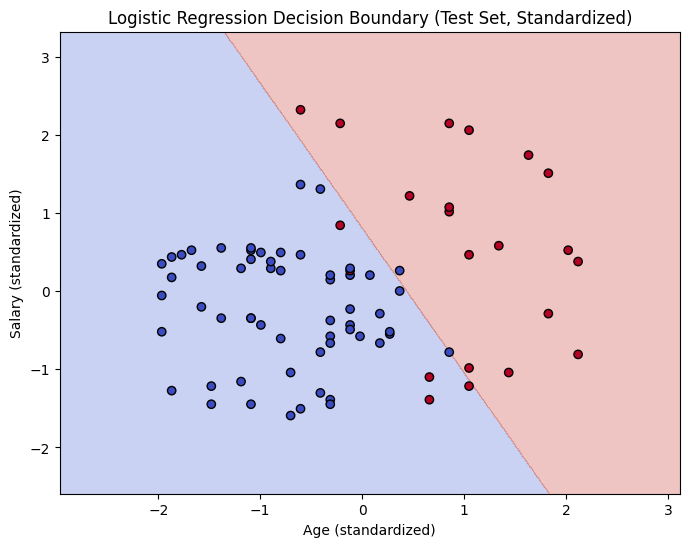

In [7]:
#Please write the code here

x_set, y_set = x_test, y_test.values

x1_min, x1_max = x_set[:, 0].min() - 1, x_set[:, 0].max() + 1
x2_min, x2_max = x_set[:, 1].min() - 1, x_set[:, 1].max() + 1
X1, X2 = np.meshgrid(
    np.arange(start=x1_min, stop=x1_max, step=0.01),
    np.arange(start=x2_min, stop=x2_max, step=0.01)
)

Z = model.predict(np.array([X1.ravel(), X2.ravel()]).T)
Z = Z.reshape(X1.shape)

plt.figure(figsize=(8,6))
plt.contourf(X1, X2, Z, alpha=0.3, cmap='coolwarm')
plt.scatter(x_set[:, 0], x_set[:, 1], c=y_set, edgecolor='k', cmap='coolwarm')
plt.title('Logistic Regression Decision Boundary (Test Set, Standardized)')
plt.xlabel('Age (standardized)')
plt.ylabel('Salary (standardized)')
plt.show()


## IV. Reflection Questions
1. Logistic regression outputs probabilities — why can it still be used for classification?

Because the logistical model uses a formula passed through a sigmoid, it is able to output the probability that a customer buys from 0-1. The classification then uses predict in order to make anything greater than .5 a buy, and less than a not buy. This applies a threshhold that allows the probabilities to be sorted into the different catagories, exactly down the line shown on the plot above. Calculating the probabilities also helps give the range of customers, rather than just black and white catagories, allowing the threshold to be chosen according to the goal of the test at hand.

2. Based on your model, which customers are more likely to purchase a car?

Based on the model, both age and higher salaries correlate with the likelihood of buying a car. Because both of their coefficients are positive, it shows a trend in both that an increase in either of the catagories will increase the likelihood. In short, older customers with a higher salary are more likely to purchase a car. However, age has a stronger correlation, ~2 v ~1, meaning that it is a more accurate indicator of the sway age has on purchasing a car.

3. What factors might cause low accuracy in this task?

Not enough variables can cause a large drop in accuracy, as changes a model cannot see can cause high likelihood customers to not purchase a car, outside fo statistics alone. Additionally, in this sorting method, the boundary is a straight line rather than a different type of graph. This means that for more nuanced measurements, the line may drastically misclassify people at the extremes of the catagories, depending on the actual trends.

4. Propose additional features or preprocessing steps that could improve accuracy.

One fix could be to switch to a polynomial approach rather than leaving it as a linear model. This will help the boundary not cutoff some of the edge cases where things may change or alter. Additionally, adding the missing context mentioned earlier would be a huge fix, as it would prevent assumptions drawn from incomplete data, and minimize the false positives/negatives, as some variables such as credit, previous car ownership, and location may have very large affects on the outcome of the purchasing decision.


#Please write your answer here